# Graph Embedding & Marginal Fisher Analysis: a 5-minute demo

**Yan et al., *Graph Embedding and Extensions: A General Framework for Dimensionality Reduction*, IEEE TPAMI 2007**

**The idea in one sentence:** PCA, LDA, ISOMAP, LLE, Laplacian Eigenmap and LPP all solve **one** problem. Draw a graph $W$ over the data, then find the embedding that keeps strongly connected points close:

$$y^* = \arg\min_{y^\top B y = d}\ \sum_{i\neq j}\|y_i-y_j\|^2 W_{ij} = \arg\min_{y^\top By=d}\ y^\top L y,\qquad L = D-W \quad\text{(Eq. 3)}$$

The algorithms differ only in the graph $W$ and the constraint $B$. Designing a new method means designing a new graph. The paper does exactly that with **Marginal Fisher Analysis (MFA)**.

**Demo outline:**
1. The framework in code
2. One solver, many algorithms
3. MFA, and where LDA fails
4. Face recognition
5. Every formula verified

*Helper cells (plotting, data loading, utilities) are folded; click a cell's left edge to expand it.*

In [1]:
# Setup and small utilities (folded)
import time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.ndimage import zoom
from scipy.sparse.csgraph import shortest_path
from scipy.spatial.distance import cdist
from sklearn.datasets import make_s_curve
from sklearn.neighbors import kneighbors_graph

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
SEED = 0


def sqdist(A, B):
    return np.maximum((A * A).sum(0)[:, None] + (B * B).sum(0)[None, :] - 2 * A.T @ B, 0.0)


def unit(P):
    """'w is the unitary projection vector' (Eq. 4): rescale every direction to length 1."""
    return P / np.maximum(np.linalg.norm(P, axis=0, keepdims=True), 1e-12)


def pca(X, n=None):
    mu = X.mean(1, keepdims=True)
    U, s, _ = np.linalg.svd(X - mu, full_matrices=False)
    U = U[:, s > s[0] * 1e-10]
    return mu, U[:, :n] if n else U

## 1. The framework in code (Sec. 2.1)

**Linearisation**, $y = X^\top w$, gives $\min\, w^\top XLX^\top w$ (Eq. 4). **Kernelisation**, $w=\sum_i\alpha_i\phi(x_i)$, gives $\min\, \alpha^\top KLK\alpha$ (Eq. 5). Both, like the direct problem, reduce to one generalised eigenproblem (Eq. 6):

$$\tilde L v = \lambda \tilde B v,\qquad\text{keep the smallest }\lambda.$$

**Tensorisation** (Eqs. 7–10) keeps each image as a matrix, $Y_i = U_1^\top \mathbf X_i U_2$. It is solved by alternating: fix $U_2$, solve a linear problem for $U_1$, and vice versa.

In [2]:
def laplacian(W):                                   # Eq. 2: L = D - W,  D_ii = sum_{j != i} W_ij
    W = np.array(W, float); np.fill_diagonal(W, 0); W = (W + W.T) / 2
    return np.diag(W.sum(1)) - W


def solve_ge(L_t, B_t, n_dims, skip=0, reg=1e-6):   # Eq. 6: L~ v = lambda B~ v, smallest lambda first
    ridge = reg * max(np.trace(B_t) / len(B_t), 1e-12)          # tiny ridge keeps B~ invertible
    vals, vecs = eigh((L_t + L_t.T) / 2, (B_t + B_t.T) / 2 + ridge * np.eye(len(B_t)))
    return vals[skip:skip + n_dims], vecs[:, skip:skip + n_dims]


def direct_embedding(W, B, n_dims, skip_trivial=True):               # Eq. 3
    return solve_ge(laplacian(W), B, n_dims, skip=int(skip_trivial))[1]


def linear_embedding(X, W, B=None, n_dims=2, reg=1e-6):               # Eq. 4: X is (m, N)
    B_t = np.eye(len(X)) if B is None else X @ B @ X.T
    return solve_ge(X @ laplacian(W) @ X.T, B_t, n_dims, reg=reg)[1]


def kernel_embedding(K, W, B=None, n_dims=2, reg=1e-6):               # Eq. 5
    B_t = K if B is None else K @ B @ K
    return solve_ge(K @ laplacian(W) @ K, B_t, n_dims, reg=reg)[1]


def tensor_embedding(T, W, Wp, dims, n_iter=8, reg=1e-4):            # Eqs. 7-10, T is (N, m1, m2)
    """Alternate: with one mode fixed, the other is a linear problem (Eq. 4) on partly projected images."""
    L, Lp = laplacian(W), laplacian(Wp)
    scatter = lambda Lap, Y: 2 * np.einsum("iar,ibr->ab", Y, (Lap @ Y.reshape(len(Y), -1)).reshape(Y.shape))
    U = [None, np.eye(T.shape[2])]
    for _ in range(n_iter):
        for o in (0, 1):
            Y = T @ U[1] if o == 0 else np.transpose(T, (0, 2, 1)) @ U[0]
            U[o] = solve_ge(scatter(L, Y), scatter(Lp, Y), dims[o], reg=reg)[1]
    return U[0], U[1]

## 2. One solver, many algorithms (Sec. 2.2, Table 1)

| Algorithm | Graph $W$ | Constraint $B$ |
|---|---|---|
| PCA | $W_{ij}=1/N$ | $I$ |
| LDA | $W_{ij}=\delta_{c_ic_j}/n_{c_i}$ | $I-\tfrac1Nee^\top$ (the PCA graph as penalty) |
| ISOMAP | $W_{ij}=\tau(D_G)_{ij}$ (geodesic distances) | $I$ |
| LLE | $W=M+M^\top-M^\top M$ | $I$ |
| Laplacian Eigenmap / LPP | $e^{-\|x_i-x_j\|^2/t}$ on $k$NN pairs | $D$ |

Below, three manifold learners that were invented separately unroll the same S-curve. Each one is **the same `direct_embedding` call** with a different $(W, B)$.

In [3]:
# Graph builders from Table 1 (folded)
def W_pca(N):
    W = np.full((N, N), 1.0 / N); np.fill_diagonal(W, 0); return W


def B_centering(N):
    return np.eye(N) - np.ones((N, N)) / N


def W_lda(y):
    y = np.asarray(y); n = np.array([np.sum(y == c) for c in y], float)
    return (y[:, None] == y[None, :]) / n[:, None]


def W_heat_knn(X, k, t=None):
    D2 = cdist(X.T, X.T, "sqeuclidean"); t = np.mean(D2) if t is None else t
    M = D2.copy(); np.fill_diagonal(M, np.inf)
    A = np.zeros_like(D2, bool); A[np.repeat(np.arange(len(D2)), k), np.argsort(M, 1)[:, :k].ravel()] = True
    A |= A.T
    return np.where(A, np.exp(-D2 / t), 0.0)


def lle_weights(X, k, reg=1e-3):
    Z = X.T; nb = np.argsort(cdist(Z, Z), 1)[:, 1:k + 1]; M = np.zeros((len(Z),) * 2)
    for i in range(len(Z)):
        G = Z[nb[i]] - Z[i]; C = G @ G.T + reg * np.trace(G @ G.T) * np.eye(k)
        w = np.linalg.solve(C, np.ones(k)); M[i, nb[i]] = w / w.sum()
    return M


def W_lle(X, k):
    M = lle_weights(X, k); return M + M.T - M.T @ M


def isomap_tau(X, k):
    DG = shortest_path(kneighbors_graph(X.T, k, mode="distance"), directed=False)
    H = np.eye(len(DG)) - 1.0 / len(DG)
    return -H @ (DG ** 2) @ H / 2

In [4]:
Xs, t_s = make_s_curve(1500, noise=0.02, random_state=SEED); Xs = Xs.T; Xs[1] *= 3; Ns = Xs.shape[1]
W_le = W_heat_knn(Xs, 10)
embeddings = {
    "ISOMAP: W = τ(D_G), B = I": direct_embedding(isomap_tau(Xs, 10), np.eye(Ns), 2, skip_trivial=False),
    "LLE: W = M+Mᵀ−MᵀM, B = I": direct_embedding(W_lle(Xs, 12), np.eye(Ns), 2),
    "Laplacian Eigenmap: B = D": direct_embedding(W_le, np.diag(W_le.sum(1)), 2),
}

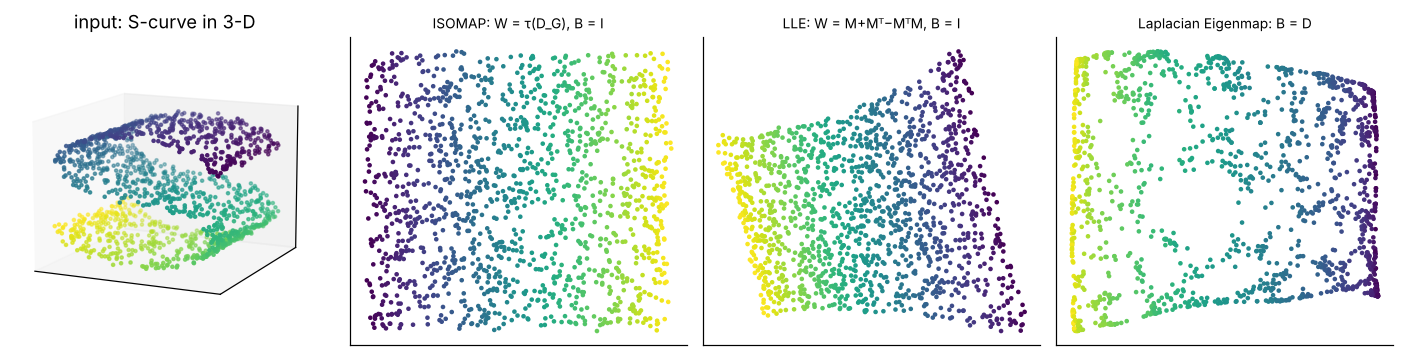

In [5]:
# Plot (folded)
fig = plt.figure(figsize=(13, 3.3))
ax = fig.add_subplot(1, 4, 1, projection="3d"); ax.scatter(*Xs, c=t_s, s=4); ax.view_init(12, -65)
ax.set_title("input: S-curve in 3-D"); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
for i, (name, Y) in enumerate(embeddings.items(), 2):
    ax = fig.add_subplot(1, 4, i); ax.scatter(Y[:, 0], Y[:, 1], c=t_s, s=4)
    ax.set_title(name, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

All three unroll the sheet, with colour flowing smoothly from edge to edge, and no line of the solver changed.

## 3. Marginal Fisher Analysis (Sec. 3)

**LDA's two limitations:**
* It assumes each class is a single Gaussian blob, because it only uses class means and scatter.
* It yields at most $N_c-1$ directions, because $S_B$ has rank at most $N_c-1$.

**MFA's fix: watch the class border, not the class centre.** It uses two graphs:
* **Intrinsic graph (Eq. 13):** link each sample to its $k_1$ nearest neighbours of the **same** class. These links are pulled together.
* **Penalty graph (Eq. 14):** for each class, link the $k_2$ **closest pairs that cross the class border**. These links are pushed apart.

$$w^* = \arg\min_w \frac{w^\top X(D-W)X^\top w}{w^\top X(D^p-W^p)X^\top w}\qquad\text{(Eq. 15)}$$

Eq. 15 is just Eq. 4 with $B = D^p - W^p$: one more call to `solve_ge`.

In [6]:
def mfa_graphs(y, k1, k2, dist):
    """Eq. 13 (intrinsic) and Eq. 14 (penalty) from a pairwise distance matrix."""
    y = np.asarray(y); W = np.zeros((len(y),) * 2); Wp = np.zeros_like(W)
    for c in np.unique(y):
        idx, out = np.flatnonzero(y == c), np.flatnonzero(y != c)
        sub = dist[np.ix_(idx, idx)].copy(); np.fill_diagonal(sub, np.inf)       # k1 same-class neighbours
        k = min(k1, len(idx) - 1)
        r, s = np.repeat(idx, k), idx[np.argsort(sub, 1)[:, :k].ravel()]
        W[r, s] = W[s, r] = 1
        sub = dist[np.ix_(idx, out)]; k = min(k2, sub.size)                    # k2 closest cross-class pairs
        r, s = np.unravel_index(np.argpartition(sub, k - 1, axis=None)[:k], sub.shape)
        Wp[idx[r], out[s]] = Wp[out[s], idx[r]] = 1
    return W, Wp


def mfa(X, y, k1, k2, n_dims):                                              # Eq. 15
    W, Wp = mfa_graphs(y, k1, k2, cdist(X.T, X.T))
    return unit(linear_embedding(X, W, laplacian(Wp), n_dims))


def lda(X, y, n_dims):                                                      # Eq. 12 in graph form
    return unit(linear_embedding(X, W_lda(y), B_centering(len(y)), n_dims))

**The non-Gaussian case (Sec. 4.2, Fig. 6).** Two classes sit in thin horizontal bands just above and below the boundary. Each class also has a far-away cluster, one upper-left and one lower-right. The correct projection is vertical. The far clusters drag the class **means** diagonally, so LDA tilts and the bands overlap. MFA only sees the border pairs.

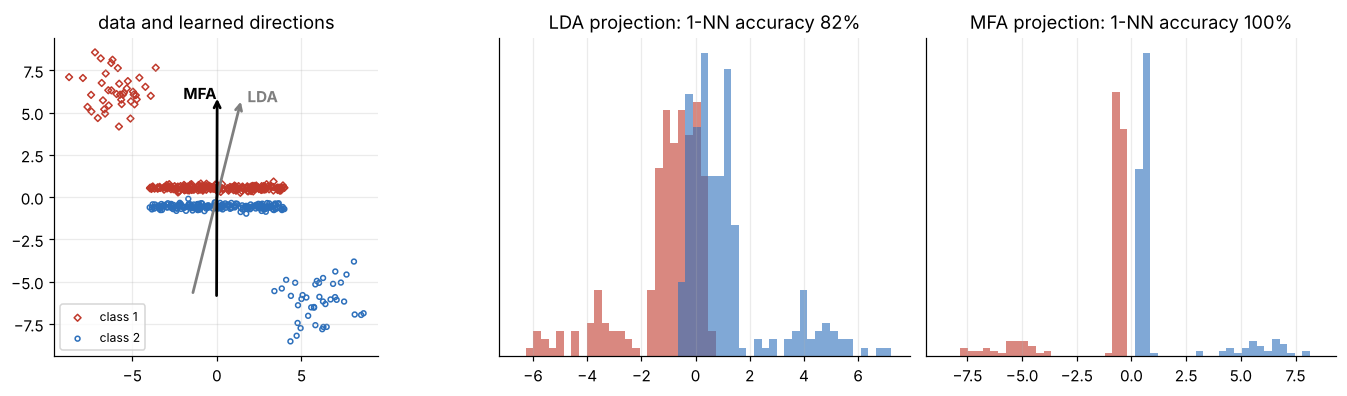

In [7]:
# Toy data, fit and plot (folded)
def toy(seed, nb=200, nc=40):
    r = np.random.default_rng(seed)
    A = np.r_[np.c_[r.uniform(-4, 4, nb), r.normal(.55, .12, nb)], np.c_[r.normal(-6, 1.2, nc), r.normal(6, 1.2, nc)]]
    B = np.r_[np.c_[r.uniform(-4, 4, nb), r.normal(-.55, .12, nb)], np.c_[r.normal(6, 1.2, nc), r.normal(-6, 1.2, nc)]]
    return np.r_[A, B].T, np.r_[np.zeros(nb + nc, int), np.ones(nb + nc, int)]


def nn_acc(Ztr, Zte, ytr, yte):
    d = (Zte ** 2).sum(0)[:, None] + (Ztr ** 2).sum(0)[None, :] - 2 * Zte.T @ Ztr
    return np.mean(ytr[np.argmin(d, 1)] == yte)


Xt, yt = toy(1); Xv, yv = toy(2)
dirs = {"LDA": lda(Xt, yt, 1)[:, 0], "MFA": mfa(Xt, yt, 5, 250, 1)[:, 0]}     # k1 = 5, k2 = 250 as in the paper
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7), gridspec_kw={"width_ratios": [1.3, 1, 1]})
ax = axes[0]
ax.scatter(*Xt[:, yt == 0], marker="D", s=10, facecolors="none", edgecolors="#c0392b", label="class 1")
ax.scatter(*Xt[:, yt == 1], marker="o", s=10, facecolors="none", edgecolors="#2c6fbb", label="class 2")
for (name, w), col in zip(dirs.items(), ["#7f7f7f", "black"]):
    u = w * np.sign(w[1])
    ax.annotate("", xy=6 * u, xytext=-6 * u, arrowprops=dict(arrowstyle="->", color=col, lw=1.8))
    ax.text(6.2 * u[0] + (0.3 if name == "LDA" else -2.0), 6.2 * u[1] - 0.4, name, color=col, fontweight="bold")
ax.set_aspect("equal"); ax.set_title("data and learned directions"); ax.legend(loc="lower left", fontsize=8)
for ax, (name, w) in zip(axes[1:], dirs.items()):
    p, q = w @ Xt, w @ Xv
    bins = np.linspace(p.min(), p.max(), 50)
    ax.hist(q[yv == 0], bins, alpha=.6, color="#c0392b"); ax.hist(q[yv == 1], bins, alpha=.6, color="#2c6fbb")
    ax.set_title(f"{name} projection: 1-NN accuracy {nn_acc(p[None], q[None], yt, yv):.0%}"); ax.set_yticks([])
plt.tight_layout(); plt.show()

LDA's direction tilts and the classes overlap. MFA's direction is vertical and separates them perfectly.

## 4. Face recognition (Sec. 4.1)

**Setup:**
* **Data:** ORL faces, 40 people × 10 photos, resized to the paper's 56×46 and histogram-equalised.
* **Protocol:** *G4/P6*. For each person, 4 random photos train and 6 test. Five random splits. A 1-nearest-neighbour classifier.
* **The comparison the paper is built on:** MFA against LDA, in each of the three extensions.

| | LDA family | MFA family |
|---|---|---|
| **Linear** | Fisherface: PCA → LDA | MFA: PCA → Eq. 15 |
| **Kernel** | KDA | KMFA (Eqs. 16–17) |
| **Tensor** | DATER | TMFA (Eq. 18) |

Each method reports its best accuracy over a small hyper-parameter grid and over output dimensions, as in the paper. *(On a machine without internet access, the notebook falls back to scikit-learn's digits.)*

In [8]:
# Load the faces and draw the random splits (folded)
def hist_eq(img):
    q = np.clip((img * 255).round().astype(int), 0, 255)
    cdf = np.cumsum(np.bincount(q.ravel(), minlength=256)).astype(float)
    return ((cdf - cdf.min()) / max(cdf.max() - cdf.min(), 1))[q]


try:
    from sklearn.datasets import fetch_olivetti_faces
    d = fetch_olivetti_faces(shuffle=False)
    images = np.stack([hist_eq(np.clip(zoom(im, (56 / 64, 46 / 64), order=1), 0, 1)) for im in d.images])
    labels, DATA, M_TRAIN, SIDE = d.target, "ORL faces (56×46)", 4, [4, 8, 16]
except Exception:
    from sklearn.datasets import load_digits
    d = load_digits(); r = np.random.default_rng(SEED)
    keep = np.sort(np.concatenate([r.permutation(np.flatnonzero(d.target == c))[:50] for c in range(10)]))
    images, labels, DATA, M_TRAIN, SIDE = d.images[keep] / 16, d.target[keep], "digits fallback (8×8)", 10, [2, 4, 6, 8]
    print("No internet: using scikit-learn digits instead of ORL.")
NC = len(np.unique(labels))
flat = lambda I: I.reshape(len(I), -1).T
r = np.random.default_rng(SEED)
splits = []
for _ in range(5):                                       # G4/P6: 4 training photos per person, the rest test
    tr = np.concatenate([r.permutation(np.flatnonzero(labels == c))[:M_TRAIN] for c in range(NC)])
    splits.append((tr, np.setdiff1d(np.arange(len(labels)), tr)))
print(f"{DATA}: {len(labels)} images of {images.shape[1]}×{images.shape[2]} pixels, {NC} classes; "
      f"{len(splits[0][0])} training / {len(splits[0][1])} test images per split")

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
No internet: using scikit-learn digits instead of ORL.
digits fallback (8×8): 500 images of 8×8 pixels, 10 classes; 100 training / 400 test images per split


**The data.** The top row shows all ten photos of one person. Expression, glasses and head pose change between them. A green frame marks the 4 photos used for training in the first split; the other 6 are test photos the classifier must recognise. The bottom row shows one photo each of ten different people.

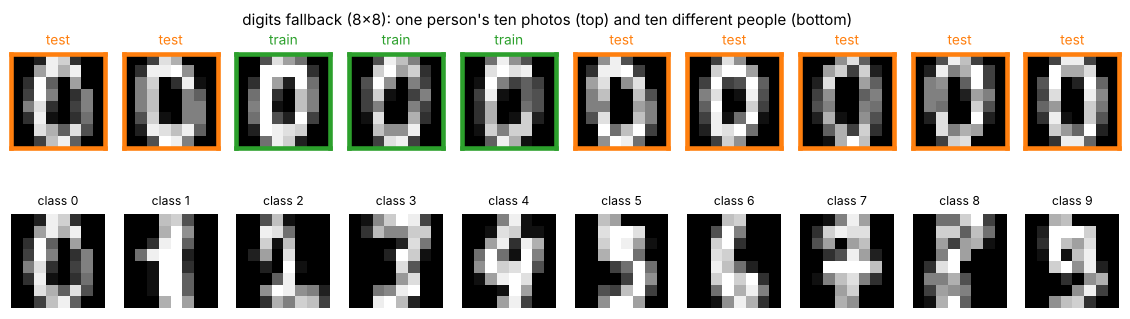

In [9]:
# Plot (folded)
person = 0
tr0 = set(splits[0][0])
fig, axes = plt.subplots(2, 10, figsize=(13, 4.0 if images.shape[1] > 20 else 3.2), gridspec_kw={"hspace": 0.45})
for ax, i in zip(axes[0], np.flatnonzero(labels == person)[:10]):
    ax.imshow(images[i], cmap="gray"); ax.set_xticks([]); ax.set_yticks([])
    col = "#2ca02c" if i in tr0 else "#ff7f0e"
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color(col); sp.set_linewidth(3)
    ax.set_title("train" if i in tr0 else "test", fontsize=9, color=col)
for ax, c in zip(axes[1], np.unique(labels)[:10]):
    ax.imshow(images[np.flatnonzero(labels == c)[0]], cmap="gray"); ax.axis("off")
    ax.set_title(f"person {c}" if images.shape[1] > 20 else f"class {c}", fontsize=8)
fig.suptitle(f"{DATA}: one person's ten photos (top) and ten different people (bottom)", fontsize=10)
plt.show()

**From input to output: one face through the MFA pipeline.** Each row follows one *test* face:
1. **Input:** the raw photo, 2,576 pixel values.
2. **Intermediate (MFA step 1):** the face as seen by PCA with $N-N_c$ components. It is drawn by mapping the PCA coordinates back to pixels, so you can see what the PCA step keeps.
3. **Output:** the face's MFA feature vector, a few dozen numbers instead of 2,576 (Eq. 15, then $w=W_{PCA}w^*$). The first 20 are shown.
4. **Result:** the training face whose MFA features are nearest, which is the 1-NN decision. ✓ means the person was recognised.

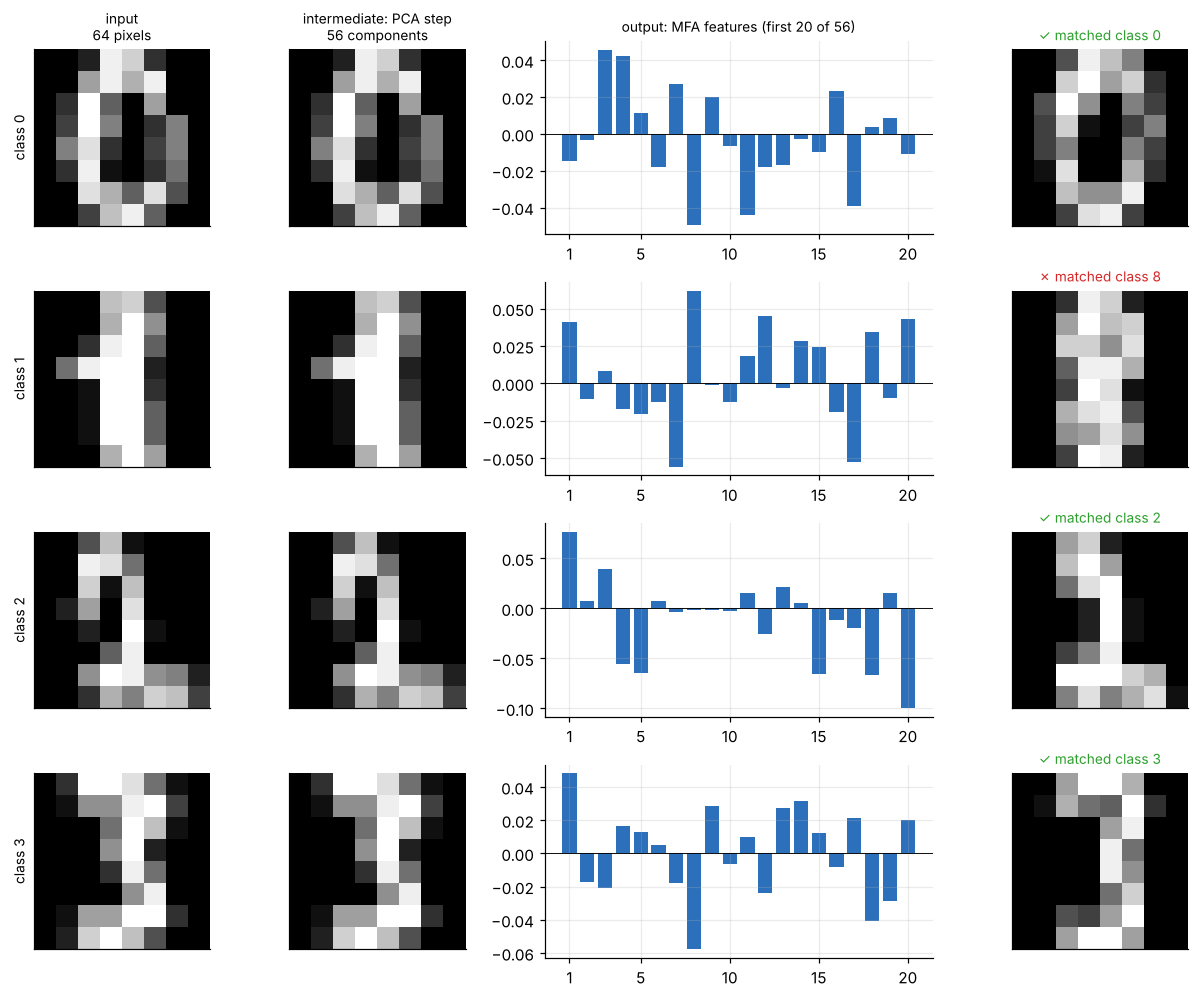

In [10]:
# Pipeline for single faces (folded); graphs use k1 = 2, k2 = 40
tr, te = splits[0]
Xtr, Xte, ytr, yte = flat(images[tr]), flat(images[te]), labels[tr], labels[te]
mu, P = pca(Xtr, len(tr) - NC)                          # step 1: PCA to N - Nc dimensions
Z, Zt = P.T @ (Xtr - mu), P.T @ (Xte - mu)
w = mfa(Z, ytr, min(2, M_TRAIN - 1), 40, len(Z))         # steps 2-3: graphs + Marginal Fisher Criterion
F, Ft = w.T @ Z, w.T @ Zt                                # step 4: features of every face
picks = [np.flatnonzero(yte == c)[0] for c in range(4)]
fig, axes = plt.subplots(len(picks), 4, figsize=(11, 2.3 * len(picks)), gridspec_kw={"width_ratios": [1, 1, 2.2, 1]})
for row, t in zip(axes, picks):
    nn = np.argmin(((F - Ft[:, [t]]) ** 2).sum(0))
    row[0].imshow(Xte[:, t].reshape(images.shape[1:]), cmap="gray")
    row[1].imshow((mu[:, 0] + P @ Zt[:, t]).reshape(images.shape[1:]), cmap="gray")
    row[2].bar(range(1, 21), Ft[:20, t], color="#2c6fbb"); row[2].axhline(0, color="black", lw=0.6)
    row[2].set_xticks([1, 5, 10, 15, 20])
    row[3].imshow(Xtr[:, nn].reshape(images.shape[1:]), cmap="gray")
    ok = ytr[nn] == yte[t]
    who = "person" if images.shape[1] > 20 else "class"
    row[3].set_title(("✓ " if ok else "✗ ") + f"matched {who} {ytr[nn]}", fontsize=9, color="#2ca02c" if ok else "#d62728")
    for a in (row[0], row[1], row[3]):
        a.set_xticks([]); a.set_yticks([])
    row[0].set_ylabel(f"{who} {yte[t]}", fontsize=9)
axes[0, 0].set_title(f"input\n{Xtr.shape[0]:,} pixels", fontsize=9)
axes[0, 1].set_title(f"intermediate: PCA step\n{P.shape[1]} components", fontsize=9)
axes[0, 2].set_title(f"output: MFA features (first 20 of {F.shape[0]})", fontsize=9)
plt.tight_layout(); plt.show()

**Latent feature plots.** Here 8 people are placed as points using the first two coordinates at each stage. Dots are training photos and crosses are test photos, and each colour is one person. For this 2-D picture, PCA keeps 8 components (one per person shown) before LDA and MFA are applied.
* **PCA (intermediate)** keeps the directions of largest variance, which mostly reflect lighting and pose, so the people overlap.
* **LDA and MFA (outputs)** pull each person's photos together. MFA does it with its local neighbour and border-pair graphs rather than class means.

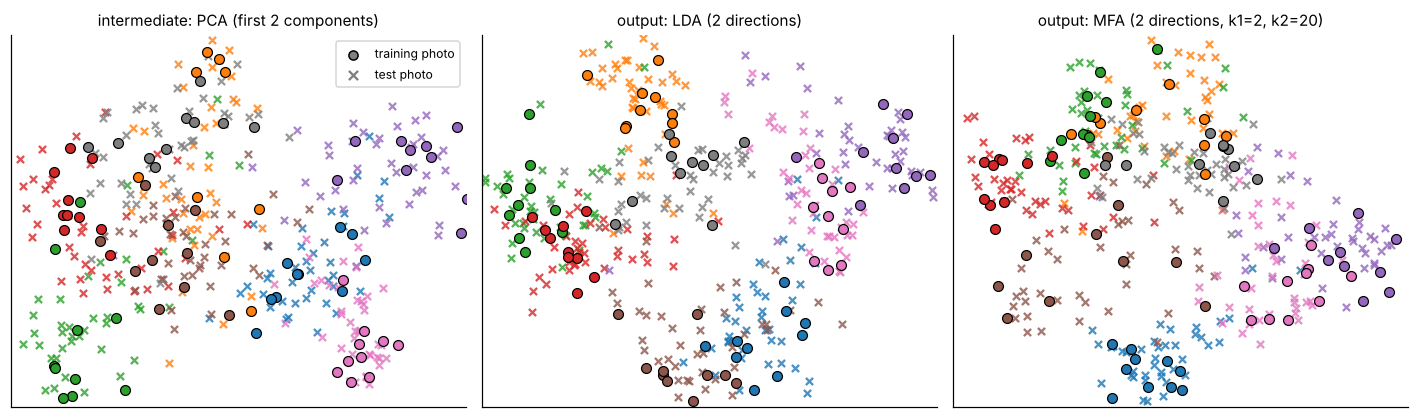

In [11]:
# Latent 2-D plots on 8 people (folded)
S = np.unique(labels)[:8]
trS = np.array([i for i in splits[0][0] if labels[i] in S]); teS = np.array([i for i in splits[0][1] if labels[i] in S])
XS, XSt, yS, ySt = flat(images[trS]), flat(images[teS]), labels[trS], labels[teS]
muS, PS = pca(XS, len(S)); ZS, ZSt = PS.T @ (XS - muS), PS.T @ (XSt - muS)
views = {"intermediate: PCA (first 2 components)": np.eye(len(ZS))[:, :2],
         "output: LDA (2 directions)": lda(ZS, yS, 2),
         f"output: MFA (2 directions, k1={min(2, M_TRAIN - 1)}, k2=20)": mfa(ZS, yS, min(2, M_TRAIN - 1), 20, 2)}
cmap = plt.get_cmap("tab10")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (title, Wv) in zip(axes, views.items()):
    Y, Yt = Wv.T @ ZS, Wv.T @ ZSt
    for k, c in enumerate(S):
        ax.scatter(*Yt[:, ySt == c], s=22, color=cmap(k), marker="x", alpha=0.8)
        ax.scatter(*Y[:, yS == c], s=42, color=cmap(k), edgecolors="black", linewidths=0.8, zorder=3)
    lo, hi = np.percentile(np.c_[Y, Yt], [1, 99], axis=1); pad = 0.05 * (hi - lo)
    ax.set_xlim(lo[0] - pad[0], hi[0] + pad[0]); ax.set_ylim(lo[1] - pad[1], hi[1] + pad[1])
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
axes[0].scatter([], [], color="grey", edgecolors="black", label="training photo")
axes[0].scatter([], [], color="grey", marker="x", label="test photo")
axes[0].legend(loc="best", fontsize=8)
plt.tight_layout(); plt.show()

In [12]:
# Methods and the experiment loop (folded): about 1 minute on a laptop
K1S, K2S, KERNEL_NS = [2, 3], [20, 40, 80, 160], [8, 10, 12]


def prefix_acc(Ztr, Zte, ytr, yte):
    """1-NN accuracy using the first d features, for every d."""
    dist = np.zeros((Zte.shape[1], Ztr.shape[1])); out = []
    for f in range(len(Ztr)):
        dist += (Zte[f][:, None] - Ztr[f][None, :]) ** 2
        out.append(np.mean(ytr[np.argmin(dist, 1)] == yte))
    return np.array(out)


def run_split(tr, te):
    """Every method on one split: returns {method: {config: accuracy-per-dimension}}."""
    Xtr, Xte, ytr, yte = flat(images[tr]), flat(images[te]), labels[tr], labels[te]
    res = {}
    mu, P = pca(Xtr); res["PCA"] = {(): prefix_acc(P.T @ (Xtr - mu), P.T @ (Xte - mu), ytr, yte)}
    mu, P = pca(Xtr, len(tr) - NC); Z, Zt = P.T @ (Xtr - mu), P.T @ (Xte - mu)     # MFA step 1: PCA to N - Nc
    w = lda(Z, ytr, NC - 1); res["Fisherface"] = {(): prefix_acc(w.T @ Z, w.T @ Zt, ytr, yte)}
    res["MFA"] = {}
    for k1 in K1S:
        for k2 in K2S:
            w = mfa(Z, ytr, k1, k2, len(Z)); res["MFA"][(k1, k2)] = prefix_acc(w.T @ Z, w.T @ Zt, ytr, yte)
    D2, D2t = sqdist(Xtr, Xtr), sqdist(Xtr, Xte)
    delta0 = np.sqrt(np.mean(np.sum((Xtr - Xtr.mean(1, keepdims=True)) ** 2, 0)))
    res["KDA"], res["KMFA"] = {}, {}
    for n in KERNEL_NS:                                                          # delta = 2^((n-10)/2.5) delta0
        K, Kt = np.exp(-D2 / (2 ** ((n - 10) / 2.5) * delta0) ** 2), np.exp(-D2t / (2 ** ((n - 10) / 2.5) * delta0) ** 2)
        lam = lambda A: A / np.sqrt(np.einsum("ip,ij,jp->p", A, K, A))[None]      # Eq. 17 normalisation
        A = lam(kernel_embedding(K, W_lda(ytr), B_centering(len(tr)), len(tr), reg=1e-4))
        res["KDA"][(n,)] = prefix_acc(A.T @ K, A.T @ Kt, ytr, yte)
        dist_k = np.sqrt(np.maximum(2 - 2 * K, 0))                               # kernel distance (Sec. 3.2)
        for k1 in K1S:
            for k2 in K2S:
                W, Wp = mfa_graphs(ytr, k1, k2, dist_k)
                A = lam(kernel_embedding(K, W, laplacian(Wp), len(tr), reg=1e-4))
                res["KMFA"][(n, k1, k2)] = prefix_acc(A.T @ K, A.T @ Kt, ytr, yte)
    T, Tt = images[tr], images[te]

    def tensor_acc(W, Wp, size):
        U1, U2 = tensor_embedding(T, W, Wp, size)
        U1, U2 = unit(U1), unit(U2)
        f = lambda I: np.einsum("ap,nab,bq->npq", U1, I, U2).reshape(len(I), -1).T
        return nn_acc(f(T), f(Tt), ytr, yte)

    mid_size = (SIDE[1], SIDE[1])                       # TMFA: pick (k1, k2) at one size, then fit every size
    tm_graphs = [mfa_graphs(ytr, k1, k2, cdist(Xtr.T, Xtr.T)) for k1 in K1S for k2 in K2S]
    best_g = max(range(len(tm_graphs)), key=lambda g: tensor_acc(*tm_graphs[g], mid_size))
    for name, (W, Wp) in [("DATER", (W_lda(ytr), W_pca(len(tr)))), ("TMFA", tm_graphs[best_g])]:
        res[name] = {(0, size): np.array([tensor_acc(W, Wp, size)]) for size in [(a, b) for a in SIDE for b in SIDE]}
    return res


t0 = time.time()
runs = [run_split(tr, te) for tr, te in splits]

METHODS = ["PCA", "Fisherface", "MFA", "KDA", "KMFA", "DATER", "TMFA"]
summary = {}
for name in METHODS:                         # best mean accuracy over configurations and output dimensions
    common = {cfg: min(len(run[name][cfg]) for run in runs) for cfg in runs[0][name]}   # lengths can differ by split
    curves = {cfg: np.mean([run[name][cfg][:common[cfg]] for run in runs], 0) for cfg in runs[0][name]}
    cfg, curve = max(curves.items(), key=lambda kv: kv[1].max())
    d = int(np.argmax(curve))
    per_split = [run[name][cfg][d] for run in runs]
    dim = f"{cfg[1][0]}×{cfg[1][1]}" if name in ("DATER", "TMFA") else d + 1
    summary[name] = dict(acc=100 * np.mean(per_split), std=100 * np.std(per_split), dim=dim, curve=curve, cfg=cfg)
n_test = len(splits[0][1]) // NC
print(f"{DATA}, G{M_TRAIN}/P{n_test}, 5 splits; ran in {time.time() - t0:.0f}s")
display(pd.DataFrame({m: {"accuracy (%)": f"{summary[m]['acc']:.1f} ± {summary[m]['std']:.1f}",
                          "best output dim": summary[m]["dim"]}
                      for m in METHODS}).T)

digits fallback (8×8), G10/P40, 5 splits; ran in 8s


,accuracy (%),best output dim
PCA,90.2 ± 0.6,46
Fisherface,75.6 ± 1.9,9
MFA,78.8 ± 1.6,18
KDA,91.1 ± 1.2,74
KMFA,90.1 ± 1.4,13
DATER,84.7 ± 1.7,6×4
TMFA,85.5 ± 1.2,6×4


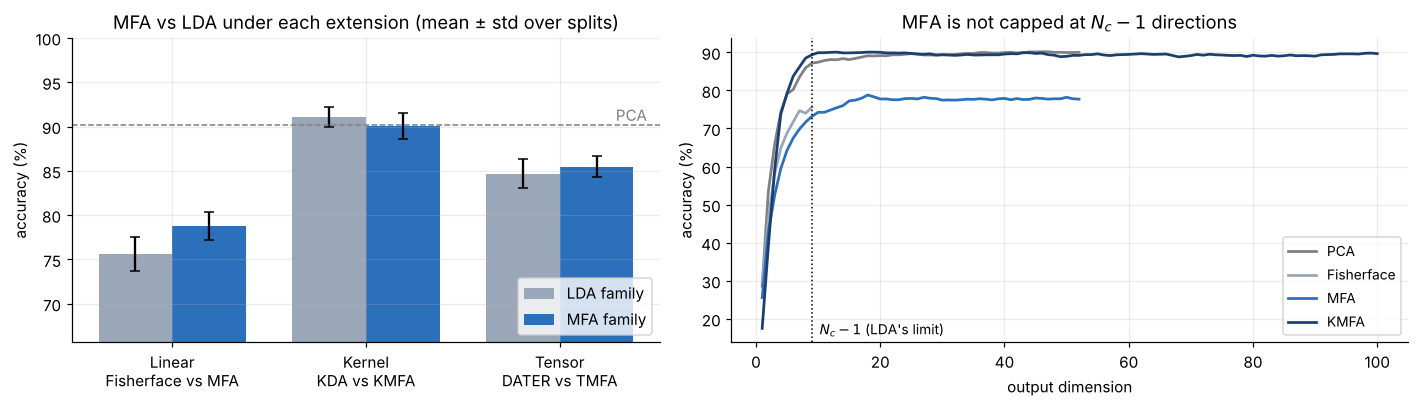

In [13]:
# Plot (folded)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
fams = [("Linear", "Fisherface", "MFA"), ("Kernel", "KDA", "KMFA"), ("Tensor", "DATER", "TMFA")]
x = np.arange(len(fams))
for j, (lab, col) in enumerate([("LDA family", "#9aa7b8"), ("MFA family", "#2c6fbb")]):
    vals = [summary[f[1 + j]]["acc"] for f in fams]; errs = [summary[f[1 + j]]["std"] for f in fams]
    ax.bar(x + (j - .5) * .38, vals, .38, yerr=errs, capsize=3, color=col, label=lab)
ax.axhline(summary["PCA"]["acc"], ls="--", color="grey", lw=1); ax.text(2.45, summary["PCA"]["acc"] + .5, "PCA", color="grey", ha="right")
ax.set_xticks(x, [f"{f[0]}\n{f[1]} vs {f[2]}" for f in fams]); ax.set_ylabel("accuracy (%)"); ax.legend(loc="lower right")
lo = min(s["acc"] - s["std"] for s in summary.values())
ax.set_ylim(max(0, lo - 8), 100); ax.set_title("MFA vs LDA under each extension (mean ± std over splits)")
ax = axes[1]
for name, col in [("PCA", "grey"), ("Fisherface", "#9aa7b8"), ("MFA", "#2c6fbb"), ("KMFA", "#1b3f73")]:
    ax.plot(np.arange(1, len(summary[name]["curve"]) + 1), 100 * summary[name]["curve"], color=col, lw=1.8, label=name)
ax.axvline(NC - 1, color="black", ls=":", lw=1); ax.text(NC - 1, ax.get_ylim()[0] + 2, "  $N_c-1$ (LDA's limit)", fontsize=9)
ax.set_xlabel("output dimension"); ax.set_ylabel("accuracy (%)"); ax.legend(loc="lower right", fontsize=9)
ax.set_title("MFA is not capped at $N_c-1$ directions")
plt.tight_layout(); plt.show()

* **Left:** the paper's central comparison, MFA against LDA in its linear, kernel and tensor forms.
* **Right:** Fisherface stops at $N_c-1$ directions. MFA and KMFA can keep using more.

## 5. Every formula verified

No official code was released, so each implementation is checked against the paper's **own formulas**. For each equation, the paper's expression is computed literally, with explicit loops and double sums, and compared with the code. "Error" is the largest difference. Values near $10^{-15}$ mean the two agree to floating-point precision.

In [14]:
# Audit (folded): literal formula vs code, on small random problems
ar = np.random.default_rng(1)
N_, C_ = 30, 3
y_ = np.repeat(np.arange(C_), N_ // C_)
X_ = ar.normal(size=(8, N_)) + 2 * ar.normal(size=(8, C_))[:, y_]
W_ = np.abs(ar.normal(size=(N_, N_))); W_ += W_.T
w_ = ar.normal(size=8)
rows = []
rel = lambda a, b: float(np.max(np.abs(np.asarray(a) - np.asarray(b))) / max(1, np.max(np.abs(b))))
pairs = [(i, j) for i in range(N_) for j in range(N_) if i != j]

lit = sum((w_ @ X_[:, i] - w_ @ X_[:, j]) ** 2 * W_[i, j] for i, j in pairs)
rows.append(("Eqs. 3–4", "Σ_{i≠j} ‖wᵀx_i − wᵀx_j‖² W_ij  =  2 wᵀXLXᵀw", rel(lit, 2 * w_ @ X_ @ laplacian(W_) @ X_.T @ w_)))
K_ = np.exp(-sqdist(X_, X_) / np.mean(sqdist(X_, X_))); a_ = ar.normal(size=N_)
lit = sum((a_ @ K_[:, i] - a_ @ K_[:, j]) ** 2 * W_[i, j] for i, j in pairs)
rows.append(("Eq. 5", "Σ ‖αᵀK_i − αᵀK_j‖² W_ij  =  2 αᵀKLKα", rel(lit, 2 * a_ @ K_ @ laplacian(W_) @ K_ @ a_)))
T_ = ar.normal(size=(N_, 6, 5)); U1_, U2_ = ar.normal(size=(6, 3)), ar.normal(size=(5, 2))
lit = sum(np.sum((U1_.T @ (T_[i] - T_[j]) @ U2_) ** 2) * W_[i, j] for i, j in pairs)
Y_ = T_ @ U2_
code = np.trace(U1_.T @ (2 * np.einsum("iar,ibr->ab", Y_, (laplacian(W_) @ Y_.reshape(N_, -1)).reshape(Y_.shape))) @ U1_)
rows.append(("Eqs. 7–8", "Σ ‖X_i×₁U₁×₂U₂ − X_j×₁U₁×₂U₂‖² W_ij  (tensor objective)", rel(lit, code)))
mu_ = X_.mean(1, keepdims=True)
SW = sum((X_[:, y_ == c] - X_[:, y_ == c].mean(1, keepdims=True)) @ (X_[:, y_ == c] - X_[:, y_ == c].mean(1, keepdims=True)).T for c in range(C_))
SB = sum(10 * (X_[:, y_ == c].mean(1, keepdims=True) - mu_) @ (X_[:, y_ == c].mean(1, keepdims=True) - mu_).T for c in range(C_))
rows.append(("Eq. 11", "N·C = X(I − eeᵀ/N)Xᵀ  (PCA graph)", rel(N_ * np.cov(X_, bias=True), X_ @ laplacian(W_pca(N_)) @ X_.T)))
rows.append(("Eq. 12", "S_W = X(I − Σ_c e^c e^cᵀ/n_c)Xᵀ  (LDA graph)", rel(SW, X_ @ laplacian(W_lda(y_)) @ X_.T)))
ev, EV = np.linalg.eig(np.linalg.solve(SW, SB))          # classical Fisher LDA; compared without the ridge
Qa = np.linalg.qr(linear_embedding(X_, W_lda(y_), B_centering(N_), C_ - 1, reg=0.0))[0]; Qb = np.linalg.qr(np.real(EV[:, np.argsort(-np.real(ev))[:C_ - 1]]))[0]
rows.append(("Eq. 12", "graph-embedding LDA spans the classical Fisher subspace", float(np.linalg.norm(Qa - Qb @ (Qb.T @ Qa), 2))))
Xc, _ = make_s_curve(120, random_state=1); tau = isomap_tau(Xc.T, 8)
rows.append(("App. A", "rows of τ(D_G) sum to 0, so ISOMAP is graph embedding", float(np.abs(tau.sum(1)).max() / np.abs(tau).max())))
M_ = lle_weights(Xc.T, 8); I_ = np.eye(len(M_))
rows.append(("App. B", "(I−M)ᵀ(I−M) = L(M + Mᵀ − MᵀM)  (LLE graph)", rel((I_ - M_).T @ (I_ - M_), laplacian(W_lle(Xc.T, 8)))))
rows.append(("Table 1 ✗", "as printed, W = M + Mᵀ + MᵀM: a sign typo in the paper", rel((I_ - M_).T @ (I_ - M_), laplacian(M_ + M_.T + M_.T @ M_))))
d_ = cdist(X_.T, X_.T); Wm, Wpm = mfa_graphs(y_, 3, 12, d_)
nn_ = {i: set(sorted([j for j in range(N_) if y_[j] == y_[i] and j != i], key=lambda j: d_[i, j])[:3]) for i in range(N_)}
W_lit = np.array([[float(i in nn_[j] or j in nn_[i]) for j in range(N_)] for i in range(N_)])
rows.append(("Eq. 13", "intrinsic graph: W_ij = 1 iff i ∈ N⁺_k1(j) or j ∈ N⁺_k1(i)", float(np.abs(Wm - W_lit).max())))
P_ = {c: set(sorted([(i, j) for i in range(N_) if y_[i] == c for j in range(N_) if y_[j] != c], key=lambda p: d_[p])[:12]) for c in range(C_)}
Wp_lit = np.array([[float(any(p in P_[y_[a]] for a in (i, j) for p in ((i, j), (j, i)))) for j in range(N_)] for i in range(N_)])
rows.append(("Eq. 14", "penalty graph: the k₂ closest cross-class pairs of each class", float(np.abs(Wpm - Wp_lit).max())))
A15, B15 = X_ @ laplacian(Wm) @ X_.T, X_ @ laplacian(Wpm) @ X_.T
w15 = mfa(X_, y_, 3, 12, 1)[:, 0]; R_ = ar.normal(size=(8, 20000))
best = (w15 @ A15 @ w15) / (w15 @ B15 @ w15) - (np.einsum("ij,ik,kj->j", R_, A15, R_) / np.einsum("ij,ik,kj->j", R_, B15, R_)).min()
rows.append(("Eq. 15", "solver beats 20,000 random directions on the MFA ratio", max(0.0, best)))
Kq = np.exp(-sqdist(X_, X_) / 50.0); Wk, Wpk = mfa_graphs(y_, 3, 12, np.sqrt(np.maximum(2 - 2 * Kq, 0)))
Aq = kernel_embedding(Kq, Wk, laplacian(Wpk), 3, reg=1e-8); Aq = Aq / np.sqrt(np.einsum("ip,ij,jp->p", Aq, Kq, Aq))[None]
rows.append(("Eq. 17", "λ = (αᵀKα)^(−1/2) makes each kernel direction unit length", float(np.abs(np.einsum("ip,ij,jp->p", Aq, Kq, Aq) - 1).max())))

audit = pd.DataFrame(rows, columns=["paper", "formula checked (literal computation vs code)", "error"])
audit["result"] = ["✗ (expected)" if p.startswith("Table") else ("✓" if e < 1e-8 else "✗") for p, e in zip(audit["paper"], audit["error"])]
audit["error"] = audit["error"].map(lambda v: f"{v:.0e}")
display(audit.style.hide(axis="index").set_properties(**{"text-align": "left"}))

paper,formula checked (literal computation vs code),error,result
Eqs. 3–4,Σ_{i≠j} ‖wᵀx_i − wᵀx_j‖² W_ij = 2 wᵀXLXᵀw,9e-16,✓
Eq. 5,Σ ‖αᵀK_i − αᵀK_j‖² W_ij = 2 αᵀKLKα,2e-15,✓
Eqs. 7–8,Σ ‖X_i×₁U₁×₂U₂ − X_j×₁U₁×₂U₂‖² W_ij (tensor objective),7e-16,✓
Eq. 11,N·C = X(I − eeᵀ/N)Xᵀ (PCA graph),3e-16,✓
Eq. 12,S_W = X(I − Σ_c e^c e^cᵀ/n_c)Xᵀ (LDA graph),2e-16,✓
Eq. 12,graph-embedding LDA spans the classical Fisher subspace,2e-15,✓
App. A,"rows of τ(D_G) sum to 0, so ISOMAP is graph embedding",2e-14,✓
App. B,(I−M)ᵀ(I−M) = L(M + Mᵀ − MᵀM) (LLE graph),4e-16,✓
Table 1 ✗,"as printed, W = M + Mᵀ + MᵀM: a sign typo in the paper",1e+00,✗ (expected)
Eq. 13,intrinsic graph: W_ij = 1 iff i ∈ N⁺_k1(j) or j ∈ N⁺_k1(i),0e+00,✓


## Takeaways

1. **One framework.** Every algorithm here, including PCA, LDA, ISOMAP, LLE, Laplacian Eigenmap, MFA and their kernel and tensor versions, is one `solve_ge` call on a different graph $(W, B)$.
2. **MFA = a better graph.** Border-pair springs remove LDA's Gaussian assumption (the toy problem) and its $N_c-1$ limit (the dimension curve).
3. **The implementation is the paper's formulas.** Each one matches a literal computation to floating-point precision. Along the way, the check caught a sign typo in the paper's Table 1.